# MS5 — Benchmark : CVRP global vs MS6 + TSP

## La question

L'architecture de production **décompose** le problème en deux : **MS6** affecte les élèves aux bus
sous contrainte de capacité (k-médoïdes capacitaire sur distance routière), puis **MS5** résout un
**TSP par bus** pour l'ordre de passage.

C'est confortable, mais *a priori* sous-optimal : l'affectation est figée **avant** de connaître le
coût des tournées qui en découlent. Un **CVRP** résout les deux décisions d'un bloc.

> **Combien nous coûte cette décomposition ?**

Le résultat est exploitable dans les deux sens — et c'est ce qui en fait un vrai benchmark :
* si le CVRP **gagne nettement**, on quantifie le prix de la décomposition ;
* s'il **gagne peu ou perd**, c'est une **validation** de MS6→MS5, car la décomposition de MS6 n'est
  pas arbitraire : elle est **géographiquement informée** (k-médoïdes sur distance routière OSRM),
  là où le CVRP part à froid.

## Le protocole (ce qui rend la comparaison honnête)

| Règle | Pourquoi |
|---|---|
| **Une seule matrice OSRM**, construite une fois ; l'approche A en extrait ses sous-matrices | Sinon on compare deux jeux de distances |
| **Même grandeur minimisée** : la durée (s) | `vrp.solve_tsp` minimise la durée ; le CVRP doit faire pareil |
| **Même arrondi entier** de la matrice | OR-Tools travaille en entiers ; même perte de précision des deux côtés |
| **Budget égalisé** : A = k TSP × B s ; B = 1 résolution de k × B s | Sinon on compare deux efforts de calcul |
| **Même nombre de bus** (k = nombre de groupes MS6) et **même capacité** | Sinon le CVRP triche en ajoutant des véhicules |

On mesure aussi le **temps de résolution** et **l'équilibrage des charges** : un CVRP qui gagne 3 %
en distance mais met dix minutes, ou qui charge un bus à 50 et un autre à 12, n'est pas un gagnant
en exploitation.

In [1]:
import os, sys, asyncio, warnings
warnings.filterwarnings("ignore")
while os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})
os.makedirs("notebooks/figures", exist_ok=True)
FIG = "notebooks/figures"
from config import settings
from osrm_client import matrice
from ms2_client import get_all_eleves
from vrp import solve_tsp, cout_tournee
from cvrp import solve_cvrp, cout_routes, charges, bus_utilises, chronometre
ECOLE = (settings.ecole_lat, settings.ecole_lng)

# Budget de résolution PAR BUS. L'approche A résout k TSP de BUDGET s chacune ;
# l'approche B reçoit donc k × BUDGET pour son unique résolution. Sans cette
# égalisation, on comparerait deux efforts de calcul différents.
BUDGET_PAR_BUS_S = 5
CAPACITE = 50          # même valeur que BUS_CAPACITY de MS6
print("Répertoire :", os.getcwd(), "| École (dépôt) :", ECOLE)

Répertoire : C:\Users\Anass\Desktop\SDIA\S9\PFE\transport-scolaire\ms5-planification | École (dépôt) : (33.893, -5.5455)


## 1. Les données réelles

On consomme les **groupes produits par MS6** (via MS2) — pas un clustering « bis » refait pour
l'occasion. Le périmètre est paramétrable : comparer sur 2, 3 puis 4 groupes permet de voir si
l'écart entre les deux approches **grandit avec la taille** du problème, ce qui est la vraie
question (un CVRP se dégrade quand l'instance grossit).

In [2]:
eleves = await get_all_eleves()
valides = [e for e in eleves
           if e.get("latitude") is not None and e.get("longitude") is not None
           and e.get("groupeId") not in (None, 999)]
groupes = {}
for e in valides:
    groupes.setdefault(e["groupeId"], []).append(e)
groupes = dict(sorted(groupes.items()))
print(f"{len(valides)} élèves répartis sur {len(groupes)} groupes MS6")
print(pd.Series({g: len(v) for g, v in groupes.items()}, name="élèves").to_string())

300 élèves répartis sur 7 groupes MS6
1    50
2    29
3    50
4    36
5    50
6    42
7    43


## 2. La matrice, construite **une seule fois**

C'est le point le plus important du protocole. Les deux approches liront **exactement les mêmes
nombres** : l'approche A extrait ses sous-matrices de la matrice globale par indexation, elle ne
refait aucun appel OSRM.

### La limite de `/table`, et comment on la contourne

OSRM plafonne `/table` à **100 coordonnées par requête** (au-delà : `400 Bad Request`). Or
`osrm_client.matrice` de MS5 fait **un seul appel** — ce qui lui suffit en production, où une tournée
compte au plus une cinquantaine d'arrêts, mais qui casse ici dès 3 groupes. Pire : le repli sur le
vol d'oiseau est **silencieux**, et comparer deux solveurs sur une matrice à vol d'oiseau ne prouve
rien sur le terrain.

On reprend donc le mécanisme de **MS6** (`ms6-clustering/osrm_client.py`) : la matrice est assemblée
**par blocs de 50×50**, chaque requête n'envoyant que l'union de deux blocs (≤ 100 coordonnées) avec
des index `sources`/`destinations` locaux.

> ⚠️ Une différence avec MS6 : **on ne symétrise pas**. MS6 fait `D = (D + Dᵀ)/2` parce qu'il lui faut
> une distance métrique pour ses k-médoïdes. Ici, l'asymétrie du réseau routier (sens uniques,
> tourne-à-gauche interdits) est précisément ce qui fait le coût réel d'une tournée — c'est l'argument
> de `verify_sens.py`. La lisser fausserait les deux approches à la fois.

In [3]:
import httpx
from osrm_client import haversine_m

BLOC = 50

async def matrice_blocs(pts):
    """Matrices (durées_s, distances_m) n×n via /table, assemblées par blocs de 50×50.

    Non symétrisée : l'asymétrie du réseau est une information, pas un bruit.
    Les paires injoignables sont comblées au vol d'oiseau (et signalées).
    """
    n = len(pts)
    blocs = [list(range(i, min(i + BLOC, n))) for i in range(0, n, BLOC)]
    dur = [[None] * n for _ in range(n)]
    dist = [[None] * n for _ in range(n)]
    sem = asyncio.Semaphore(4)

    async with httpx.AsyncClient(timeout=120.0) as client:
        async def fetch(bi, bj):
            idx = bi + bj
            coords = ";".join(f"{pts[k][1]},{pts[k][0]}" for k in idx)
            s = ";".join(str(i) for i in range(len(bi)))
            d = ";".join(str(i) for i in range(len(bi), len(idx)))
            url = (f"{settings.osrm_url}/table/v1/driving/{coords}"
                   f"?annotations=duration,distance&sources={s}&destinations={d}")
            async with sem:
                r = await client.get(url)
            r.raise_for_status()
            j = r.json()
            for a, gi in enumerate(bi):
                for b, gj in enumerate(bj):
                    dur[gi][gj] = j["durations"][a][b]
                    dist[gi][gj] = j["distances"][a][b]

        await asyncio.gather(*(fetch(bi, bj) for bi in blocs for bj in blocs))

    trous = 0
    for i in range(n):
        for j in range(n):
            if dur[i][j] is None or dist[i][j] is None or dur[i][j] < 0 or dist[i][j] < 0:
                trous += 1
                d = haversine_m(pts[i], pts[j]) * 1.4
                dist[i][j] = d
                dur[i][j] = d / (30 * 1000 / 3600)
    if trous:
        print(f"  ⚠ {trous} paires injoignables comblées au vol d'oiseau")
    return dur, dist


async def construire_perimetre(n_groupes: int):
    """(ids_groupes, élèves ordonnés, durées, distances) sur une matrice UNIQUE école + élèves."""
    ids = list(groupes)[:n_groupes]
    ens = [e for g in ids for e in groupes[g]]
    pts = [ECOLE] + [(e["latitude"], e["longitude"]) for e in ens]
    dur, dist = await matrice_blocs(pts)
    return ids, ens, dur, dist


# Contrôle : la matrice est-elle bien du VRAI routier ? Le vol d'oiseau produit une
# symétrie parfaite ; OSRM, non.
ids, ens, dur, dist = await construire_perimetre(len(groupes))
asym = sum(1 for i in range(1, 20) for j in range(1, 20) if abs(dur[i][j] - dur[j][i]) > 1)
print(f"{len(ens)} élèves · matrice {len(dur)}×{len(dur)} · "
      f"{asym} paires asymétriques sur 361 testées → {'OSRM réel' if asym else '⚠ repli'}")
maxi = len(groupes)

  ⚠ 5 paires injoignables comblées au vol d'oiseau
300 élèves · matrice 301×301 · 328 paires asymétriques sur 361 testées → OSRM réel


## 3. Les deux approches, sur la même instance

In [4]:
def approche_A(ids, ens, dur, dist, budget_s):
    """MS6 + TSP : sous-matrices extraites de la matrice globale (aucun nouvel appel OSRM)."""
    routes_glob, t_total = [], 0.0
    for g in ids:
        idx = [0] + [i + 1 for i, e in enumerate(ens) if e["groupeId"] == g]
        sub = [[dur[a][b] for b in idx] for a in idx]
        order, t = chronometre(solve_tsp, sub, 0, budget_s)
        t_total += t
        routes_glob.append([idx[i] for i in order])   # réindexation vers le global
    return routes_glob, t_total


def approche_B(ids, ens, dur, dist, budget_s):
    """CVRP global : k véhicules, capacité 50, une seule résolution."""
    (routes, ok), t = chronometre(
        solve_cvrp, dur, n_vehicules=len(ids), capacite=CAPACITE,
        depot=0, time_limit_s=budget_s)
    return (routes if ok else None), t


def mesurer(nom, routes, dur, dist, t_solve):
    ch = [c for c in charges(routes) if c > 0]
    return {"approche": nom,
            "duree_min": cout_routes(routes, dur) / 60,
            "distance_km": cout_routes(routes, dist) / 1000,
            "bus_utilises": bus_utilises(routes),
            "charge_min": min(ch) if ch else 0,
            "charge_max": max(ch) if ch else 0,
            "ecart_type_charge": float(np.std(ch)) if ch else 0.0,
            "temps_resolution_s": round(t_solve, 2)}

## 4. Exécution — l'écart grandit-il avec la taille de l'instance ?

In [5]:
lignes, detail = [], {}
for k in range(2, maxi + 1):
    ids, ens, dur, dist = await construire_perimetre(k)
    budget_A = BUDGET_PAR_BUS_S                 # par bus
    budget_B = BUDGET_PAR_BUS_S * len(ids)      # même effort total

    rA, tA = await asyncio.to_thread(approche_A, ids, ens, dur, dist, budget_A)
    rB, tB = await asyncio.to_thread(approche_B, ids, ens, dur, dist, budget_B)

    mA = mesurer("MS6 + TSP", rA, dur, dist, tA)
    mB = mesurer("CVRP global", rB, dur, dist, tB) if rB else None
    for m in (mA, mB):
        if m:
            m["groupes"], m["eleves"] = k, len(ens)
            lignes.append(m)
    detail[k] = (ids, ens, dur, dist, rA, rB)

    if mB:
        ecart = (mA["duree_min"] - mB["duree_min"]) / mA["duree_min"] * 100
        gagnant = "CVRP" if ecart > 0 else "découpage MS6"
        print(f"  {k} groupes ({len(ens)} élèves) : A={mA['duree_min']:.1f} min | "
              f"B={mB['duree_min']:.1f} min | écart {ecart:+.1f} % en faveur du {gagnant}")
    else:
        print(f"  {k} groupes : le CVRP n'a pas trouvé de solution en {budget_B} s "
              f"— résultat en soi, à consigner tel quel")

tab = pd.DataFrame(lignes)[["groupes", "eleves", "approche", "duree_min", "distance_km",
                            "bus_utilises", "charge_min", "charge_max",
                            "ecart_type_charge", "temps_resolution_s"]]
tab.round(2)

  ⚠ 3 paires injoignables comblées au vol d'oiseau


  2 groupes (79 élèves) : A=59.4 min | B=59.2 min | écart +0.2 % en faveur du CVRP


  ⚠ 5 paires injoignables comblées au vol d'oiseau


  3 groupes (129 élèves) : A=74.3 min | B=76.0 min | écart -2.3 % en faveur du découpage MS6


  ⚠ 5 paires injoignables comblées au vol d'oiseau


...

  ⚠ 5 paires injoignables comblées au vol d'oiseau


  6 groupes (257 élèves) : A=164.1 min | B=163.9 min | écart +0.1 % en faveur du CVRP


  ⚠ 5 paires injoignables comblées au vol d'oiseau


  7 groupes (300 élèves) : A=207.1 min | B=208.0 min | écart -0.4 % en faveur du découpage MS6


,groupes,eleves,approche,duree_min,distance_km,bus_utilises,charge_min,charge_max,ecart_type_charge,temps_resolution_s
0,2,79,MS6 + TSP,59.38,30.53,2,29,50,10.50,10.01
1,2,79,CVRP global,59.24,30.29,2,29,50,10.50,10.00
2,3,129,MS6 + TSP,74.34,36.99,3,29,50,9.90,15.00
3,3,129,CVRP global,76.03,38.36,3,29,50,9.90,15.00
4,4,165,MS6 + TSP,100.24,49.65,4,29,50,9.09,20.00
5,4,165,CVRP global,100.89,50.42,4,29,50,9.09,20.01
6,5,215,MS6 + TSP,135.84,66.47,5,29,50,8.85,25.01
7,5,215,CVRP global,137.70,67.71,5,32,49,5.83,25.03
8,6,257,MS6 + TSP,164.09,79.78,6,29,50,8.09,30.02
9,6,257,CVRP global,163.86,79.55,6,28,50,7.56,30.02


## 5. Contrôle de cohérence

L'approche A doit retrouver l'ordre de grandeur déjà mesuré en production. Sur le **groupe 1** des
données v2, `/api/planification/tournee?groupeId=1` donne **~17,24 km / ~36,0 min**.

> Attention à ne pas surinterpréter un écart de quelques pour cent : `solve_tsp` utilise
> `GUIDED_LOCAL_SEARCH` **borné en temps** (5 s). Ce n'est pas un algorithme déterministe à budget
> fixé — deux exécutions sur la même machine, sous des charges différentes, explorent un nombre
> d'itérations différent et peuvent rendre deux tournées voisines mais distinctes. Un écart de
> **±3 %** est du bruit de solveur ; un écart de 20 % signalerait un vrai problème (matrice ou
> affectation changée).

In [6]:
idx1 = [0] + [i + 1 for i, e in enumerate(ens) if e["groupeId"] == ids[0]]
sub_d = [[dist[a][b] for b in idx1] for a in idx1]
sub_t = [[dur[a][b] for b in idx1] for a in idx1]
o = solve_tsp(sub_t, 0, BUDGET_PAR_BUS_S)
km, mn = cout_tournee(o, sub_d) / 1000, cout_tournee(o, sub_t) / 60
print(f"Groupe {ids[0]} ({len(idx1)-1} élèves) : {km:.2f} km | {mn:.2f} min")
print(f"Référence production        : ~17.24 km | ~36.0 min")
print(f"Écart                       : {(km-17.24)/17.24*100:+.1f} % en distance, "
      f"{(mn-36.0)/36.0*100:+.1f} % en durée")

Groupe 1 (50 élèves) : 16.71 km | 35.27 min
Référence production        : ~17.24 km | ~36.0 min
Écart                       : -3.1 % en distance, -2.0 % en durée


## 6. Lecture des résultats

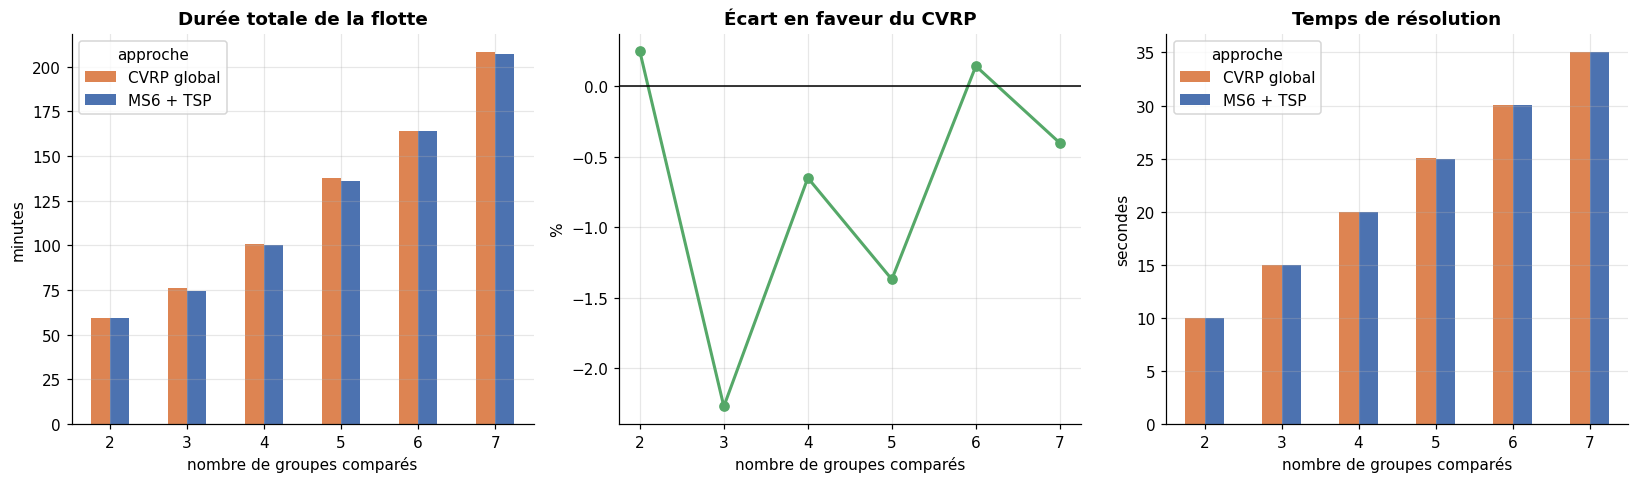

In [7]:
piv = tab.pivot(index="groupes", columns="approche", values="duree_min")
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))

piv.plot(kind="bar", ax=ax[0], color=["#DD8452", "#4C72B0"], rot=0)
ax[0].set_title("Durée totale de la flotte"); ax[0].set_ylabel("minutes")
ax[0].set_xlabel("nombre de groupes comparés")

if "CVRP global" in piv:
    ecart = (piv["MS6 + TSP"] - piv["CVRP global"]) / piv["MS6 + TSP"] * 100
    ax[1].plot(ecart.index, ecart.values, "-o", color="#55A868", lw=2)
    ax[1].axhline(0, color="k", lw=1)
    ax[1].set_title("Écart en faveur du CVRP"); ax[1].set_ylabel("%")
    ax[1].set_xlabel("nombre de groupes comparés")

tab.pivot(index="groupes", columns="approche", values="temps_resolution_s").plot(
    kind="bar", ax=ax[2], color=["#DD8452", "#4C72B0"], rot=0)
ax[2].set_title("Temps de résolution"); ax[2].set_ylabel("secondes")
ax[2].set_xlabel("nombre de groupes comparés")

plt.tight_layout(); plt.savefig(f"{FIG}/06_cvrp_vs_ms6_tsp.png", bbox_inches="tight"); plt.show()

## 7. Équilibrage des charges

Une métrique que la seule distance masque : le CVRP peut gagner quelques pour cent en **déséquilibrant**
les bus (un à 50 élèves, un à 12). En exploitation c'est un mauvais échange — le temps à bord des
enfants du bus chargé explose, ce qui est précisément ce que le projet cherche à réduire.

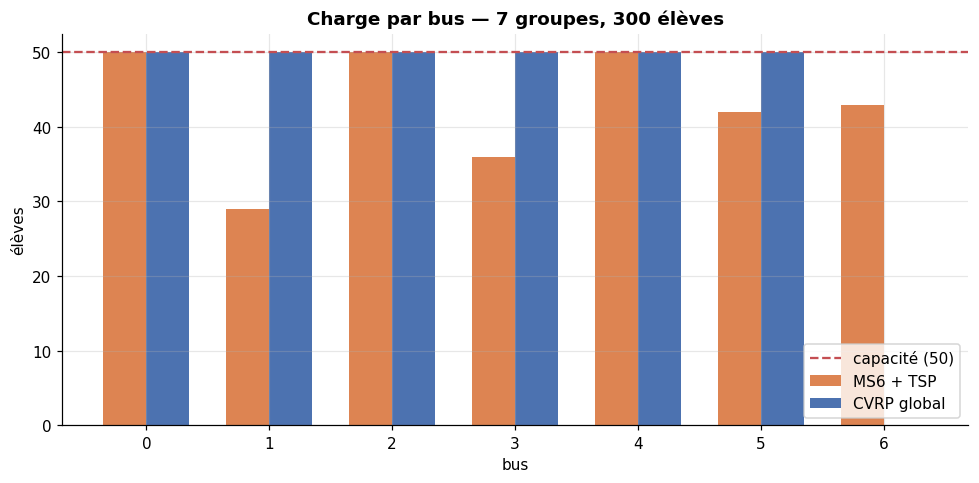

   approche  charge_min  charge_max  ecart_type_charge
  MS6 + TSP          29          50           7.491492
CVRP global          50          50           0.000000


In [8]:
k_max = int(tab["groupes"].max())
ids, ens, dur, dist, rA, rB = detail[k_max]
cA = [c for c in charges(rA) if c > 0]
cB = [c for c in charges(rB) if c > 0] if rB else []

fig, ax = plt.subplots(figsize=(9, 4.5))
n = max(len(cA), len(cB)); x = np.arange(n); l = 0.35
ax.bar(x - l/2, cA + [0]*(n-len(cA)), l, label="MS6 + TSP", color="#DD8452")
if cB:
    ax.bar(x + l/2, cB + [0]*(n-len(cB)), l, label="CVRP global", color="#4C72B0")
ax.axhline(CAPACITE, color="#C44E52", ls="--", lw=1.5, label=f"capacité ({CAPACITE})")
ax.set_title(f"Charge par bus — {k_max} groupes, {len(ens)} élèves")
ax.set_xlabel("bus"); ax.set_ylabel("élèves"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/06_equilibrage_charges.png", bbox_inches="tight"); plt.show()

print(tab[tab.groupes == k_max][["approche", "charge_min", "charge_max",
                                 "ecart_type_charge"]].to_string(index=False))

## 8. Conclusion — mesurée sur les 300 élèves

### 8.1 En durée de conduite : la décomposition ne coûte rien

| Groupes | Élèves | MS6 + TSP | CVRP global | Écart |
|--:|--:|--:|--:|:--|
| 2 | 79 | 59,4 min | 59,2 min | +0,2 % CVRP |
| 3 | 129 | 74,3 min | 76,0 min | −2,3 % **MS6** |
| 4 | 165 | 100,2 min | 100,9 min | −0,7 % **MS6** |
| 5 | 215 | 135,8 min | 137,7 min | −1,4 % **MS6** |
| 6 | 257 | 164,1 min | 163,9 min | +0,1 % CVRP |
| 7 | **300** | **207,1 min** | **208,0 min** | **−0,4 % MS6** |

À budget de calcul égalisé, **le CVRP ne bat jamais la décomposition de plus de 0,2 %**, et lui est
le plus souvent inférieur (jusqu'à −2,3 %). Le résultat attendu — « résoudre les deux décisions
ensemble doit faire mieux » — **n'est pas au rendez-vous**.

**Pourquoi.** MS6 n'est pas un découpage arbitraire que le CVRP pourrait facilement battre : ses
k-médoïdes travaillent **déjà sur la distance routière OSRM**. L'information géographique est donc
injectée *avant* le routage. Le CVRP, lui, doit la redécouvrir seul, sur un espace de recherche
bien plus vaste (affectation × routage) et dans le même budget de temps. La décomposition n'est pas
une approximation subie : c'est une **façon d'injecter de la connaissance du domaine dans le
solveur**, et elle est payante.

### 8.2 En revanche, le CVRP trouve autre chose : un bus de moins

Sur les 7 groupes, avec 7 véhicules **disponibles**, il n'en utilise que **6** — chargés à
**50/50 exactement** (écart-type des charges : **0,00**), contre 7 bus chargés de 29 à 50 pour MS6
(écart-type **7,49**).

> **Un bus économisé, donc un chauffeur, pour +0,4 % de temps de conduite.**

Ce n'est pas une erreur de MS6, c'est un **arbitrage différent**. Le minimum théorique est
⌈300 / 50⌉ = 6 bus ; MS6 en choisit 7 parce que sa courbe de Pareto privilégie la **compacité
géographique**. Ce 7ᵉ bus achète deux choses que le tableau de durées ne montre pas :

* des tournées plus compactes, donc moins de temps à bord pour les enfants ;
* de la **marge** — le CVRP à 6 bus pleins n'en a aucune : **un élève de plus rend l'instance
  infaisable**, alors qu'une inscription en cours d'année est le cas normal dans une école.

### 8.3 Et le coût de calcul ne se lit pas dans le tableau

Les temps de résolution sont identiques **par construction** (budget égalisé). Mais l'approche A est
faite de **k TSP indépendants**, donc parallélisable : c'est exactement ce que fait
`POST /api/planification/tournees` avec `asyncio.gather` (43 s → 9 s mesuré). Un CVRP de 300 arrêts
ne se découpe pas — son budget est incompressible.

### 8.4 Verdict

**On garde MS6 + TSP.** Non par confort d'architecture, mais parce que c'est ce que dit la mesure :
la décomposition ne coûte rien en conduite, se parallélise, et laisse de la marge de capacité.

Le CVRP reste utile comme **outil de dimensionnement de flotte** : c'est lui qui répond à « combien
de bus me faut-il au minimum ? », question à laquelle MS6 ne répond pas puisqu'il optimise la
compacité. Une piste : le relancer avec `cout_fixe_vehicule` élevé pour explorer le compromis
« flotte minimale ↔ temps à bord ».

> Quel que soit le verdict, il est **mesuré**. C'est la différence entre « j'ai choisi de décomposer »
> et « j'ai comparé deux formulations du même problème, et je sais laquelle gagne, de combien, et à
> quel prix ».